<a href="https://colab.research.google.com/github/Handinoasa/PCVK_2026/blob/main/Week7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week7 — Segmentasi Citra dengan Thresholding

- Nama: Handino Asa Galih
- Nim: 244107020237
- Kelas: TI 3E

## 1–2. Setup — Mount Google Drive & Import Library

Sesuai instruksi tugas, hubungkan Colab dengan Google Drive lalu import library yang dibutuhkan.

In [1]:
import os, sys, warnings
warnings.filterwarnings("ignore")

import numpy as np
import cv2
import matplotlib.pyplot as plt
from collections import deque

from skimage import data, filters, measure, morphology, segmentation
from sklearn.cluster import KMeans

IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
    except Exception as e:
        print("Mount Drive dilewati:", e)
else:
    print("Bukan lingkungan Colab — melewati mount Google Drive.")

print("Versi OpenCV :", cv2.__version__)
print("Siap dijalankan.")

Mounted at /content/drive
Versi OpenCV : 5.0.0
Siap dijalankan.


### Pencari lokasi citra (otomatis Colab / lokal)

Fungsi `resolve_image()` mencari berkas citra di beberapa lokasi kandidat sehingga notebook
tetap berjalan baik di Colab maupun di komputer lokal.

In [8]:
KANDIDAT_DIR = [
    "/content/drive/MyDrive/Images",                       # Colab (struktur modul)
    "/content/drive/MyDrive",                              # Colab (alternatif)
    "/content/drive/MyDrive/Images-20260929T103314Z-1-001/Images",
    r"D:\SMT 5\Images-20260929T103314Z-1-001\Images",       # lokal
    r"D:\SMT 5\Media\Images-20260917T075020Z-1-001\Images",
    r"D:\SMT 5",                                            # lokal
    "Images", "images", ".",                                     # relatif
]

# Nama alternatif jika berkas utama tidak ditemukan
ALIAS = {
    "lena_gs_lc2.jpg": ["lena_gs_lc2.jpg", "lena_gs_lc.jpg", "lena.jpg"],
    "gradient.jpg":    ["gradient.jpg", "lena.jpg"],
    "ktp_fulan.jpg":   ["ktp_fulan.jpg", "ktp1.jpg", "ktp.jpg"],
    "ktp_fulani.jpg":  ["ktp_fulani.jpg", "ktp.jpg"],
}

def resolve_image(nama, pakai_alias=True):
    """Cari berkas citra. Prioritas: nama persis di semua folder, baru alias."""
    # 1) cari nama persis
    for d in KANDIDAT_DIR:
        p = os.path.join(d, nama)
        if os.path.exists(p):
            return p
    # 2) baru cari nama alternatif
    if pakai_alias:
        for d in KANDIDAT_DIR:
            for nm in ALIAS.get(nama, []):
                p = os.path.join(d, nm)
                if os.path.exists(p):
                    return p
    raise FileNotFoundError(
        "Berkas '{}' tidak ditemukan. Letakkan di salah satu folder:\n  {}".format(
            nama, "\n  ".join(KANDIDAT_DIR))
    )

for f in ["ktp_fulan.jpg", "ktp_fulani.jpg", "sudoku-original.jpg", "lena_gs_lc2.jpg"]:
    try:
        print("{:22s} -> {}".format(f, resolve_image(f)))
    except FileNotFoundError as e:
        print("{:22s} -> (belum tersedia)".format(f))

ktp_fulan.jpg          -> /content/drive/MyDrive/Images/ktp_fulan.jpg
ktp_fulani.jpg         -> /content/drive/MyDrive/Images/ktp_fulani.jpg
sudoku-original.jpg    -> /content/drive/MyDrive/Images/sudoku-original.jpg
lena_gs_lc2.jpg        -> /content/drive/MyDrive/Images/lena_gs_lc.jpg


## 3. Global Threshold manual (threshold = 200)

Dibuat **tanpa** `cv.threshold()` — hanya memakai operasi NumPy sesuai persamaan pada modul.

| Jenis | Jika piksel > thresh | Jika piksel <= thresh |
|---|---|---|
| BINARY | maxval (255) | 0 |
| BINARY_INV | 0 | maxval (255) |
| TRUNC | thresh | nilai asli |
| TOZERO | nilai asli | 0 |
| TOZERO_INV | 0 | nilai asli |

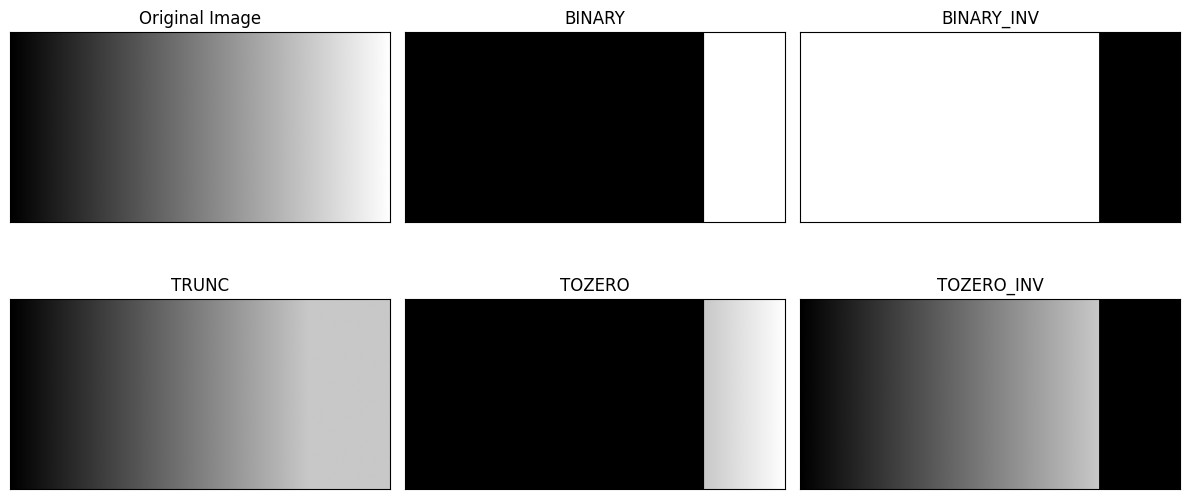

In [11]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

def global_threshold(gray, thresh, maxval, jenis):
    """Implementasi manual 5 jenis global threshold memakai NumPy."""
    if jenis == "BINARY":
        out = np.where(gray > thresh, maxval, 0)
    elif jenis == "BINARY_INV":
        out = np.where(gray > thresh, 0, maxval)
    elif jenis == "TRUNC":
        out = np.where(gray > thresh, thresh, gray)
    elif jenis == "TOZERO":
        out = np.where(gray > thresh, gray, 0)
    elif jenis == "TOZERO_INV":
        out = np.where(gray > thresh, 0, gray)
    else:
        raise ValueError("Jenis threshold tidak dikenal: " + jenis)
    return out.astype(np.uint8)

# --- Buat citra gradien hitam (kiri) -> putih (kanan) ---
tinggi, lebar = 256, 512
gradasi = np.linspace(0, 255, lebar)                 # 0 ... 255 sepanjang lebar
gray_gt = np.tile(gradasi, (tinggi, 1)).astype(np.uint8)   # ulangi ke semua baris

thresh, maxval = 200, 255
jenis_list = ["BINARY", "BINARY_INV", "TRUNC", "TOZERO", "TOZERO_INV"]
hasil_gt   = {j: global_threshold(gray_gt, thresh, maxval, j) for j in jenis_list}

judul  = ["Original Image"] + jenis_list
gambar = [gray_gt] + [hasil_gt[j] for j in jenis_list]

plt.figure(figsize=(12, 6))
for i, (g, t) in enumerate(zip(gambar, judul)):
    plt.subplot(2, 3, i + 1)
    plt.imshow(g, "gray", vmin=0, vmax=255)
    plt.title(t)
    plt.xticks([]); plt.yticks([])
plt.tight_layout()
plt.show()

## 4. Adaptive Threshold manual (Mean & Gaussian) — citra Sudoku

Dibuat **tanpa** `cv.threshold()`, `cv.adaptiveThreshold()`, maupun filter siap pakai.
Filter rata-rata dan Gaussian dihitung manual memakai *sliding window* NumPy.

- Global threshold manual: ambang **127**
- Ukuran jendela: **11 x 11**
- Konstanta **C = 2**, **sigma = 2** untuk Gaussian

Rumus: `T(x,y) = rata-rata_local(x,y) - C`, piksel menjadi putih bila `I(x,y) > T(x,y)`.

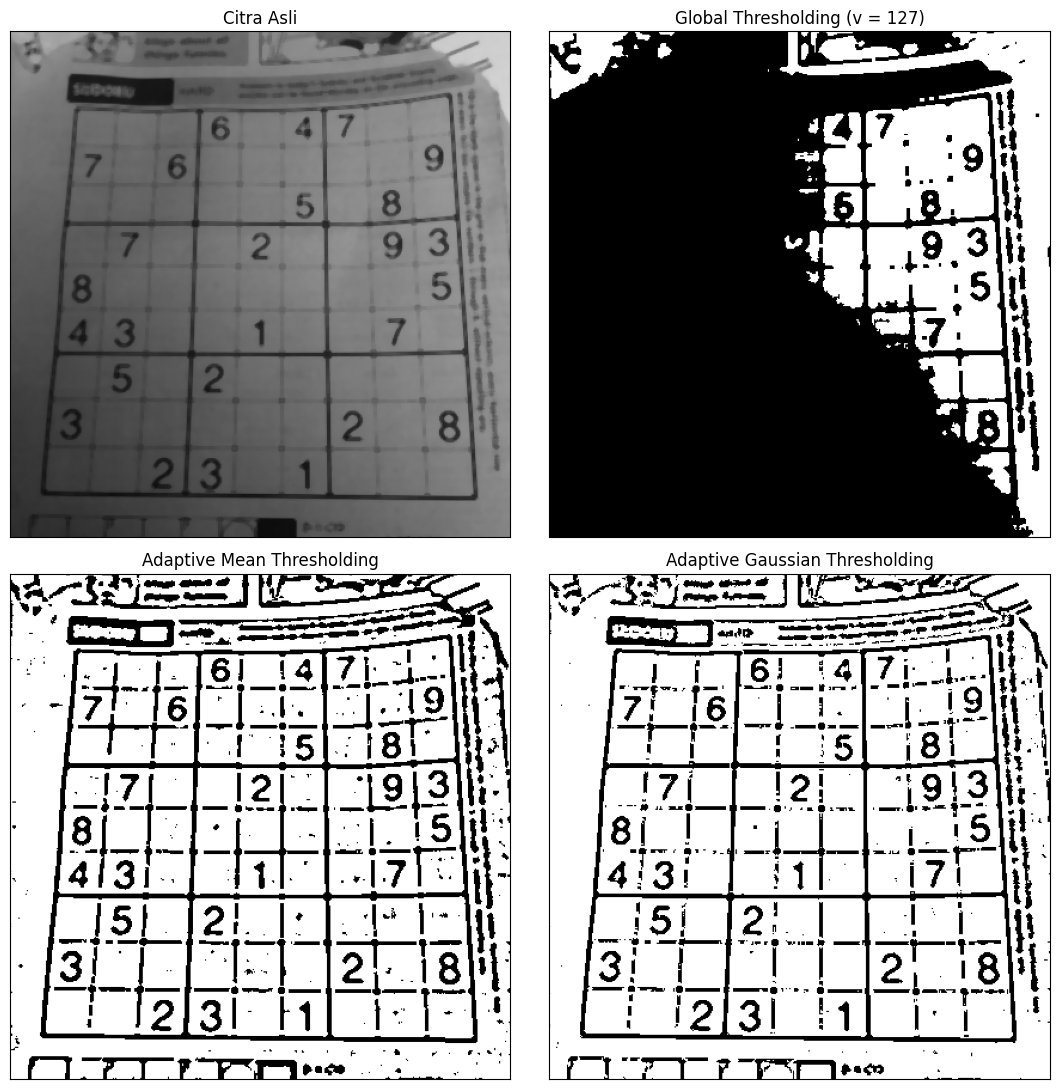

In [9]:
def _sliding_windows(arr, k):
    """Ambil semua jendela k x k memakai stride tricks (padding reflect)."""
    pad = k // 2
    ap  = np.pad(arr.astype(np.float64), pad, mode="reflect")
    return np.lib.stride_tricks.sliding_window_view(ap, (k, k))

def manual_mean_filter(arr, k):
    return _sliding_windows(arr, k).mean(axis=(-1, -2))

def gaussian_kernel(size, sigma):
    ax = np.arange(size) - size // 2
    xx, yy = np.meshgrid(ax, ax)
    kern = np.exp(-(xx ** 2 + yy ** 2) / (2.0 * sigma ** 2))
    return kern / kern.sum()

def manual_gaussian_filter(arr, size, sigma):
    kern = gaussian_kernel(size, sigma)
    return np.tensordot(_sliding_windows(arr, size), kern, axes=([-1, -2], [0, 1]))

def adaptive_mean(gray, block, C):
    lokal = manual_mean_filter(gray, block)
    return np.where(gray > lokal - C, 255, 0).astype(np.uint8)

def adaptive_gaussian(gray, block, C, sigma):
    lokal = manual_gaussian_filter(gray, block, sigma)
    return np.where(gray > lokal - C, 255, 0).astype(np.uint8)

# --- Citra Sudoku (pencahayaan tidak merata) ---
sudoku = cv2.imread(resolve_image("sudoku-original.jpg"))
sudoku = cv2.medianBlur(sudoku, 5)
gray_sudoku = cv2.cvtColor(sudoku, cv2.COLOR_BGR2GRAY)

global_127 = global_threshold(gray_sudoku, 127, 255, "BINARY")
adap_mean  = adaptive_mean(gray_sudoku, block=11, C=2)
adap_gauss = adaptive_gaussian(gray_sudoku, block=11, C=2, sigma=2)

judul = ["Citra Asli", "Global Thresholding (v = 127)",
         "Adaptive Mean Thresholding", "Adaptive Gaussian Thresholding"]
gambar = [gray_sudoku, global_127, adap_mean, adap_gauss]

plt.figure(figsize=(11, 11))
for i, (g, t) in enumerate(zip(gambar, judul)):
    plt.subplot(2, 2, i + 1)
    plt.imshow(g, "gray", vmin=0, vmax=255)
    plt.title(t); plt.xticks([]); plt.yticks([])
plt.tight_layout(); plt.show()

## 5A. Otsu Threshold manual — citra Lena low-contrast

Otsu dihitung **tanpa library** (mencari nilai threshold yang memaksimalkan *between-class variance*),
lalu dibandingkan dengan global threshold 127 dan hasil library OpenCV.

Berkas Lena           : lena_gs_lc2 disimulasikan dari lena_gs_lc.jpg (rentang 85-108)
Rentang intensitas    : 85 .. 107
Median                : 96.0
Threshold Otsu manual : 95
Threshold Otsu library: 94.0
Piksel > 127 (global) : 0.00%


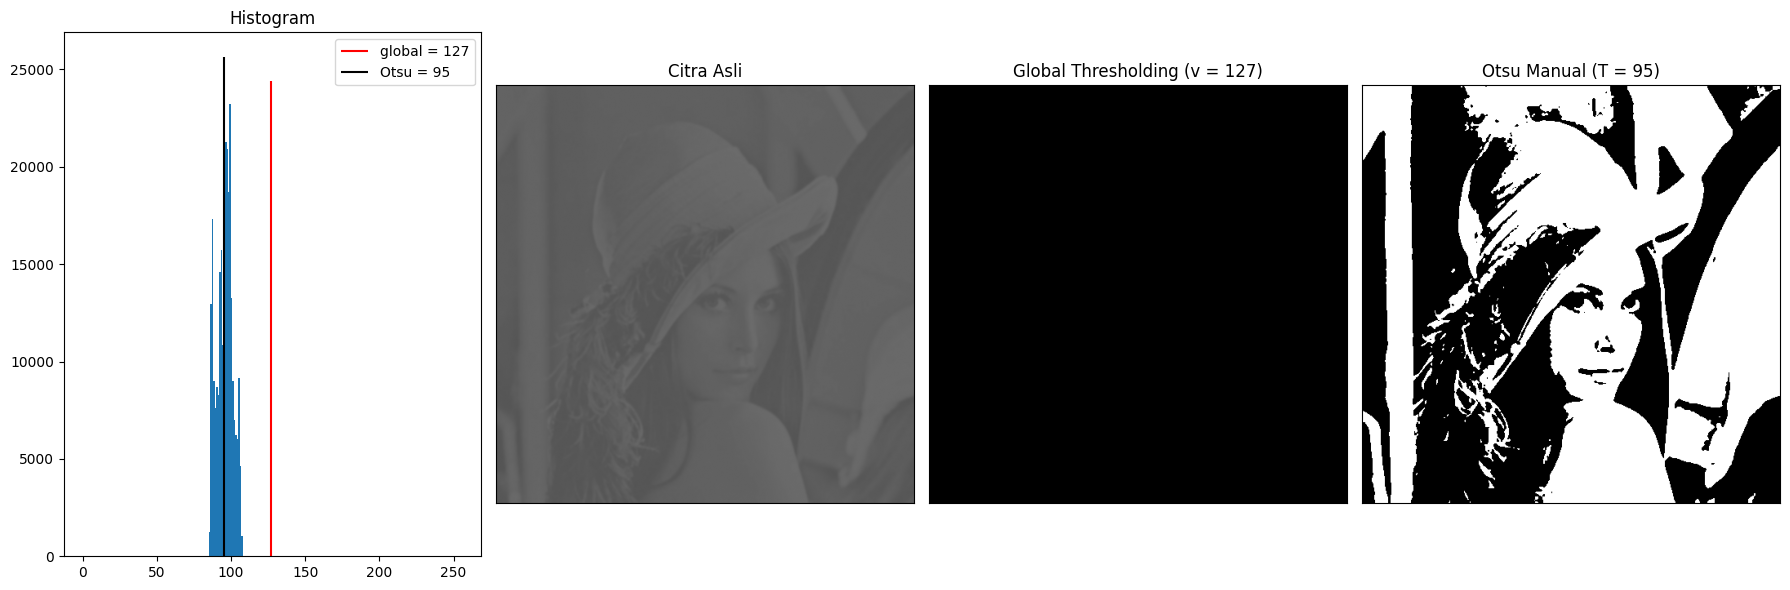

In [12]:
def otsu_manual(gray):
    """Otsu tanpa library. Mengembalikan (citra biner, nilai threshold)."""
    gray = gray.astype(np.uint8)
    pixel_number = gray.shape[0] * gray.shape[1]
    mean_weight  = 1.0 / pixel_number
    his, _ = np.histogram(gray, np.arange(0, 257))
    intensity_arr = np.arange(256)
    final_thresh, final_value = -1, -1.0
    for t in range(1, 256):
        pcb = np.sum(his[:t]); pcf = np.sum(his[t:])
        if pcb == 0 or pcf == 0:
            continue
        Wb = pcb * mean_weight; Wf = pcf * mean_weight
        mub = np.sum(intensity_arr[:t] * his[:t]) / float(pcb)
        muf = np.sum(intensity_arr[t:] * his[t:]) / float(pcf)
        value = Wb * Wf * (mub - muf) ** 2      # between-class variance
        if value > final_value:
            final_thresh, final_value = t, value
    out = gray.copy()
    out[gray > final_thresh] = 255
    out[gray <= final_thresh] = 0
    return out, final_thresh

def buat_low_contrast(gray, lo=85, hi=108):
    """Regangkan intensitas ke rentang [lo, hi] untuk meniru lena_gs_lc2."""
    g = gray.astype(np.float64)
    g = (g - g.min()) / (g.max() - g.min() + 1e-9) * (hi - lo) + lo
    return np.clip(g, lo, hi).astype(np.uint8)

# --- Citra Lena low contrast (lena_gs_lc2 bila ada; jika tidak, disimulasikan) ---
try:
    lena_path = resolve_image("lena_gs_lc2.jpg", pakai_alias=False)
    lena = cv2.imread(lena_path, 0)
    lena_info = lena_path
except FileNotFoundError:
    lena = cv2.imread(resolve_image("lena_gs_lc.jpg"), 0)
    lena = buat_low_contrast(lena, 85, 108)
    lena_info = "lena_gs_lc2 disimulasikan dari lena_gs_lc.jpg (rentang 85-108)"

blur = cv2.GaussianBlur(lena, (5, 5), 0)

otsu_biner, otsu_thresh = otsu_manual(blur)
ret, global_bin = cv2.threshold(blur, 127, 255, cv2.THRESH_BINARY)

# hasil Otsu dengan library sebagai pembanding
ret_lib, otsu_lib = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

print("Berkas Lena           :", lena_info)
print("Rentang intensitas    : {} .. {}".format(int(blur.min()), int(blur.max())))
print("Median                :", float(np.median(blur)))
print("Threshold Otsu manual :", otsu_thresh)
print("Threshold Otsu library:", ret_lib)
print("Piksel > 127 (global) : {:.2f}%".format((blur > 127).mean() * 100))

judul = ["Citra Asli", "Global Thresholding (v = 127)",
         "Otsu Manual (T = {})".format(otsu_thresh)]
gambar = [blur, global_bin, otsu_biner]

plt.figure(figsize=(18, 6))
plt.subplot(1, 4, 1)
plt.hist(blur.ravel(), 256, [0, 256])
plt.vlines(127, 0, plt.ylim()[1], colors="red", label="global = 127")
plt.vlines(otsu_thresh, 0, plt.ylim()[1], colors="black", label="Otsu = {}".format(otsu_thresh))
plt.title("Histogram"); plt.legend()
for i, (g, t) in enumerate(zip(gambar, judul)):
    plt.subplot(1, 4, i + 2)
    plt.imshow(g, "gray", vmin=0, vmax=255)
    plt.title(t); plt.xticks([]); plt.yticks([])
plt.tight_layout(); plt.show()

### Jawaban Pertanyaan (5A)

**Mengapa Binary Thresholding bisa menghasilkan citra hitam seluruhnya?**
Karena aturan BINARY menetapkan piksel menjadi putih hanya jika `I(x,y) > T`. Bila **seluruh**
nilai intensitas citra berada di bawah ambang T, maka tidak ada satu pun piksel yang lolos,
sehingga semua piksel bernilai 0 (hitam).

Pada citra Lena low-contrast versi modul (`lena_gs_lc2.jpg`) rentang intensitasnya sangat sempit
(sekitar 85–108), sehingga ambang tetap **127** berada **di atas seluruh histogram** → hasilnya
hitam total. Otsu berhasil karena ia menghitung ambang dari histogram sehingga T jatuh **di dalam**
rentang tersebut dan tetap memisahkan objek dan latar.

> Catatan: berkas `lena_gs_lc2.jpg` tidak disertakan pada media, sehingga notebook membuat
> versi low-contrast (rentang 85–108) dari `lena_gs_lc.jpg` agar perilaku *all-black* sesuai
> ilustrasi modul. Bila Anda meletakkan `lena_gs_lc2.jpg` asli di folder citra, notebook
> otomatis memakainya.

**Berapa ambang agar gambar Lena masih terlihat?** Ambang harus berada **di dalam** rentang
intensitas citra (mis. nilai **median** atau nilai **Otsu**). Nilai tepatnya dicetak otomatis
pada keluaran sel di atas — gunakan angka `Threshold Otsu manual` (sekitar **92–96** untuk citra
low-contrast).

## 5B. Otsu vs Global Threshold pada citra KTP sendiri

Perbandingan hasil Otsu manual dengan global threshold biasa pada citra KTP milik sendiri.

Rentang intensitas KTP : 15 .. 255
Threshold Otsu KTP     : 166


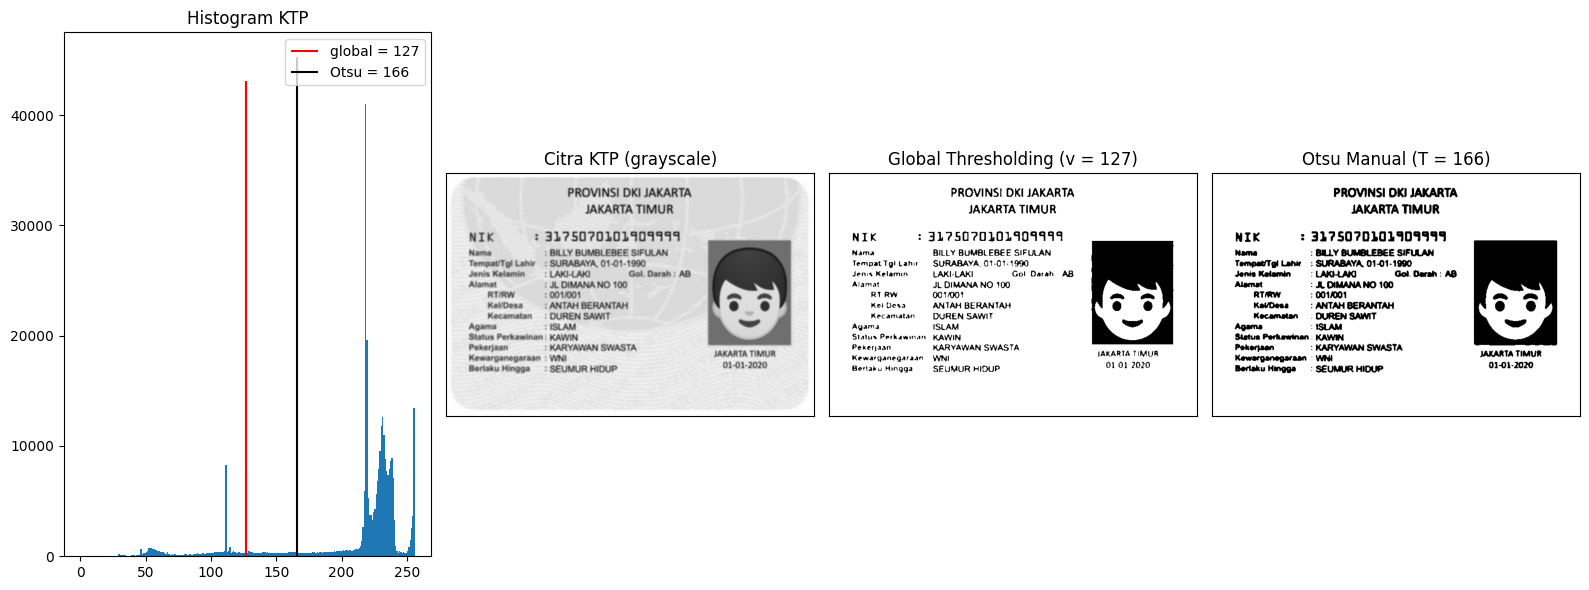

In [13]:
ktp_gray = cv2.imread(resolve_image("ktp_fulan.jpg"), 0)
ktp_blur = cv2.GaussianBlur(ktp_gray, (5, 5), 0)

ktp_otsu_bin, ktp_otsu_T = otsu_manual(ktp_blur)
ret, ktp_global_bin = cv2.threshold(ktp_blur, 127, 255, cv2.THRESH_BINARY)

print("Rentang intensitas KTP : {} .. {}".format(int(ktp_blur.min()), int(ktp_blur.max())))
print("Threshold Otsu KTP     :", ktp_otsu_T)

judul = ["Citra KTP (grayscale)", "Global Thresholding (v = 127)",
         "Otsu Manual (T = {})".format(ktp_otsu_T)]
gambar = [ktp_blur, ktp_global_bin, ktp_otsu_bin]

plt.figure(figsize=(16, 6))
plt.subplot(1, 4, 1)
plt.hist(ktp_blur.ravel(), 256, [0, 256])
plt.vlines(127, 0, plt.ylim()[1], colors="red", label="global = 127")
plt.vlines(ktp_otsu_T, 0, plt.ylim()[1], colors="black", label="Otsu = {}".format(ktp_otsu_T))
plt.title("Histogram KTP"); plt.legend()
for i, (g, t) in enumerate(zip(gambar, judul)):
    plt.subplot(1, 4, i + 2)
    plt.imshow(g, "gray", vmin=0, vmax=255)
    plt.title(t); plt.xticks([]); plt.yticks([])
plt.tight_layout(); plt.show()

## 6A. Segmentasi berbasis region — Region Growing pada `data.coins()`

Tiga seed dipilih otomatis:
- **seed koin** — pusat koin terbesar,
- **seed latar** — sudut citra,
- **seed tepi** — piksel pada batas koin.

Region growing dijalankan untuk **T = 5, 20, 60** dan ditampilkan dalam grid **3 x 3**.

Seed: {'Seed dalam koin': (22, 90), 'Seed latar': (5, 5), 'Seed tepi koin': (22, 129)} | nilai seed koin = 116


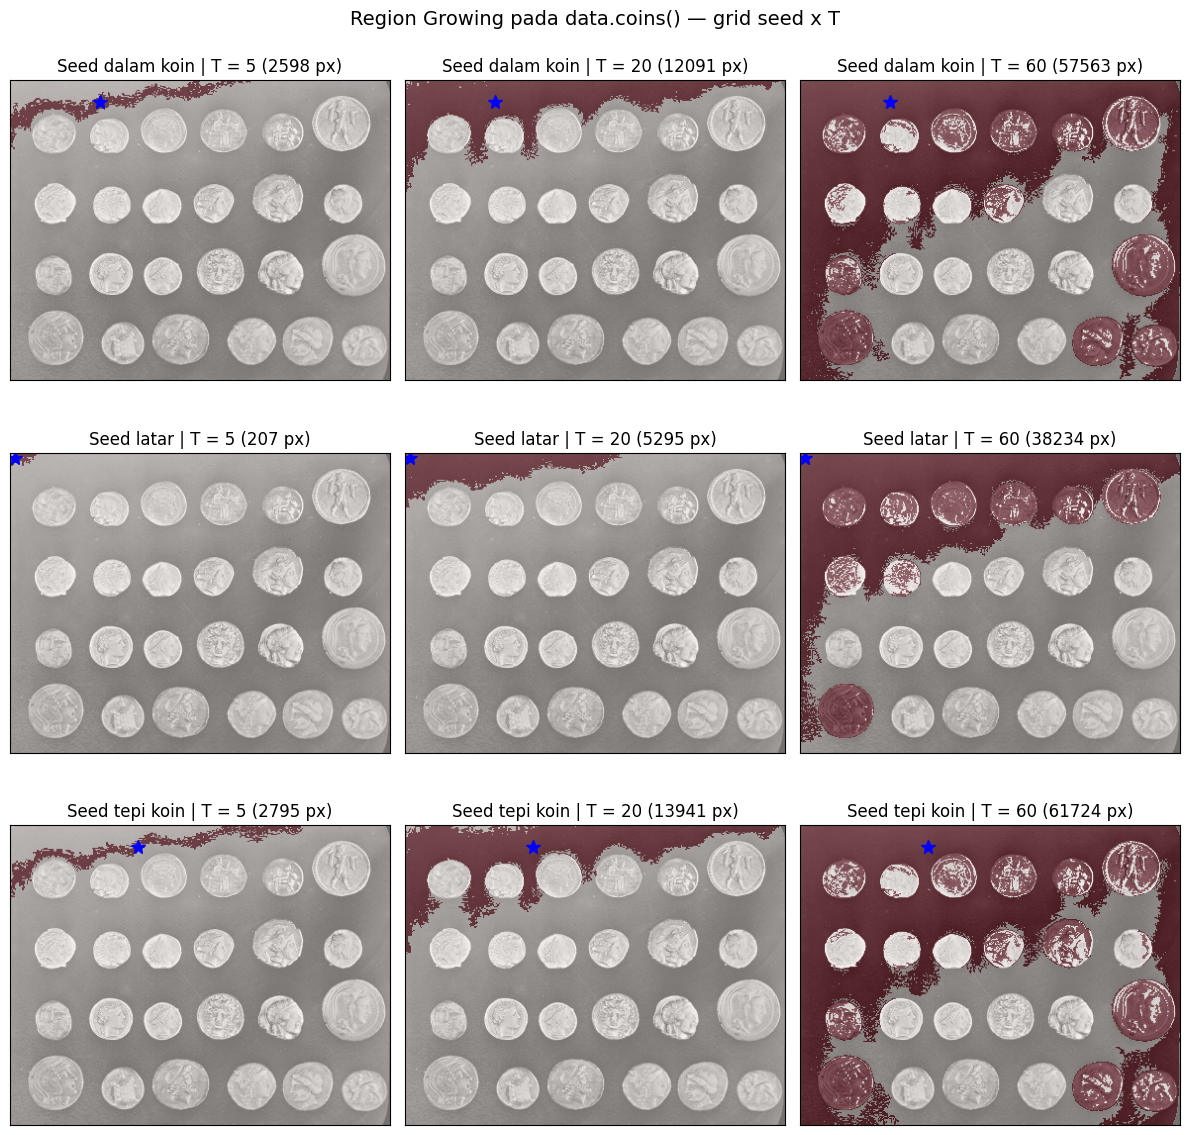

In [14]:
coins = data.coins()

# --- deteksi seed otomatis ---
t_otsu = filters.threshold_otsu(coins)
mask_coin = coins > t_otsu
lab = measure.label(mask_coin)
props = sorted(measure.regionprops(lab), key=lambda p: p.area, reverse=True)
koin = props[0]
cy, cx = int(koin.centroid[0]), int(koin.centroid[1])

tepi_mask = (lab == koin.label) & (~morphology.erosion(lab == koin.label, morphology.disk(2)))
ys, xs = np.where(tepi_mask)
ey, ex = int(ys[len(ys) // 2]), int(xs[len(xs) // 2])

seeds = {"Seed dalam koin": (cy, cx), "Seed latar": (5, 5), "Seed tepi koin": (ey, ex)}
print("Seed:", seeds, "| nilai seed koin =", coins[cy, cx])

def region_growing(img, seed, T):
    h, w = img.shape
    out = np.zeros((h, w), np.uint8)
    vis = np.zeros((h, w), bool)
    dq = deque([seed]); vis[seed] = True
    nilai = float(img[seed])
    tetangga = [(-1, -1), (-1, 0), (-1, 1), (0, -1), (0, 1), (1, -1), (1, 0), (1, 1)]
    while dq:
        y, x = dq.popleft(); out[y, x] = 255
        for dy, dx in tetangga:
            ny, nx = y + dy, x + dx
            if 0 <= ny < h and 0 <= nx < w and not vis[ny, nx] \
               and abs(float(img[ny, nx]) - nilai) < T:
                vis[ny, nx] = True
                dq.append((ny, nx))
    return out

T_list = [5, 20, 60]
plt.figure(figsize=(12, 12))
i = 1
for nama_seed, (sy, sx) in seeds.items():
    for T in T_list:
        hasil = region_growing(coins, (sy, sx), T)
        plt.subplot(3, 3, i)
        plt.imshow(coins, "gray")
        plt.imshow(hasil, "Reds", alpha=0.45)
        plt.plot(sx, sy, "b*", markersize=10)
        plt.title("{} | T = {} ({} px)".format(nama_seed, T, int((hasil > 0).sum())))
        plt.xticks([]); plt.yticks([])
        i += 1
plt.suptitle("Region Growing pada data.coins() — grid seed x T", fontsize=14)
plt.tight_layout(); plt.show()

**Interpretasi:** semakin besar **T**, region makin mudah "bocor" ke area bertetangga
sehingga mask makin luas; **T** terlalu kecil hanya menghasilkan bercak kecil di sekitar seed.
Seed di latar menghasilkan region latar, seed di tepi menghasilkan region yang mengikuti tepi koin.

## 6B. Segmentasi region dengan `skimage.segmentation.flood()`

`flood()` menerima piksel terhubung yang berada dalam **toleransi** terhadap intensitas seed.

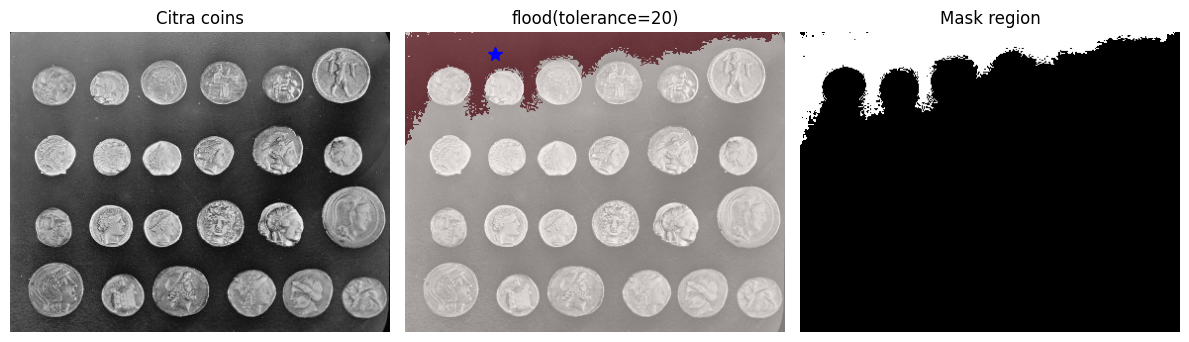

Jumlah piksel region (flood): 12524


In [15]:
tol = 20
flood_mask = segmentation.flood(coins, (cy, cx), tolerance=tol)

plt.figure(figsize=(12, 5))
plt.subplot(1, 3, 1); plt.imshow(coins, "gray"); plt.title("Citra coins"); plt.axis("off")
plt.subplot(1, 3, 2)
plt.imshow(coins, "gray"); plt.imshow(flood_mask, "Reds", alpha=0.5)
plt.plot(cx, cy, "b*", markersize=10)
plt.title("flood(tolerance={})".format(tol)); plt.axis("off")
plt.subplot(1, 3, 3); plt.imshow(flood_mask, "gray"); plt.title("Mask region"); plt.axis("off")
plt.tight_layout(); plt.show()

print("Jumlah piksel region (flood):", int(flood_mask.sum()))

## 7. Segmentasi warna KTP dengan K-Means — hanya warna biru

K-Means mengelompokkan piksel warna; cluster yang berada pada rentang warna biru HSV
(`85 <= H <= 130`, `S >= 25`, `V >= 40`) dipertahankan, sisanya dihitamkan.

Cluster biru terdeteksi: [4] | pusat RGB: [[198, 227, 244]]
IoU  (K-Means vs HSV): 0.6158
Dice (K-Means vs HSV): 0.7622


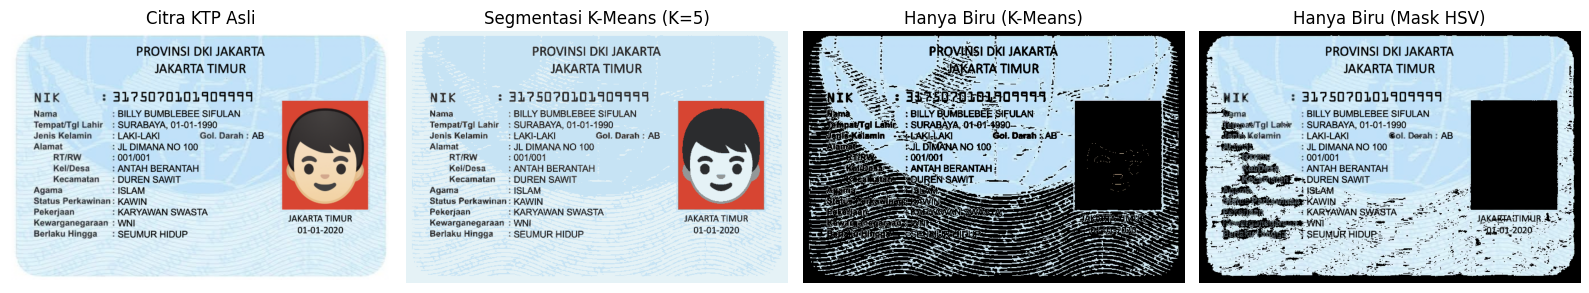

In [16]:
ktp_rgb = cv2.cvtColor(cv2.imread(resolve_image("ktp_fulan.jpg")), cv2.COLOR_BGR2RGB)
Z = ktp_rgb.reshape(-1, 3).astype(np.float32)

K = 5
kmeans = KMeans(n_clusters=K, random_state=42, n_init=10).fit(Z)
labels = kmeans.labels_
centers = np.uint8(kmeans.cluster_centers_)

# tentukan cluster biru berdasarkan warna pusat (HSV)
centers_hsv = cv2.cvtColor(centers.reshape(1, -1, 3), cv2.COLOR_RGB2HSV).reshape(-1, 3)
biru = [i for i in range(K)
        if 85 <= centers_hsv[i][0] <= 130
        and centers_hsv[i][1] >= 25
        and centers_hsv[i][2] >= 40]
print("Cluster biru terdeteksi:", biru, "| pusat RGB:", [centers[i].tolist() for i in biru])

# citra tersegmentasi (semua cluster -> warna pusat)
segmented = centers[labels.flatten()].reshape(ktp_rgb.shape)

# hanya biru: piksel di luar cluster biru dihitamkan
mask_biru = np.isin(labels, biru).reshape(ktp_rgb.shape[:2])
hanya_biru = ktp_rgb.copy()
hanya_biru[~mask_biru] = 0

# pembanding: mask HSV langsung (petunjuk modul)
hsv_img = cv2.cvtColor(ktp_rgb, cv2.COLOR_RGB2HSV)
H, S, V = hsv_img[..., 0], hsv_img[..., 1], hsv_img[..., 2]
mask_hsv = (H >= 85) & (H <= 130) & (S >= 25) & (V >= 40)
hanya_biru_hsv = ktp_rgb.copy(); hanya_biru_hsv[~mask_hsv] = 0

# evaluasi kuantitatif IoU & Dice antara mask K-Means dan mask HSV
inter = np.logical_and(mask_biru, mask_hsv).sum()
union = np.logical_or(mask_biru, mask_hsv).sum()
iou  = inter / union if union else 0
dice = 2 * inter / (mask_biru.sum() + mask_hsv.sum()) if (mask_biru.sum() + mask_hsv.sum()) else 0
print("IoU  (K-Means vs HSV): {:.4f}".format(iou))
print("Dice (K-Means vs HSV): {:.4f}".format(dice))

plt.figure(figsize=(16, 6))
for i, (g, t) in enumerate([
        (ktp_rgb, "Citra KTP Asli"),
        (segmented, "Segmentasi K-Means (K={})".format(K)),
        (hanya_biru, "Hanya Biru (K-Means)"),
        (hanya_biru_hsv, "Hanya Biru (Mask HSV)")]):
    plt.subplot(1, 4, i + 1)
    plt.imshow(g); plt.title(t); plt.axis("off")
plt.tight_layout(); plt.show()

## D2. Tugas Kelompok — OCR: citra berwarna vs Otsu vs Adaptive

Langkah: install Tesseract + model bahasa Indonesia, lalu bandingkan pembacaan teks pada
tiga citra KTP: **(1) berwarna asli, (2) hasil Otsu, (3) hasil Adaptive Threshold**.

In [17]:
# Install Tesseract + bahasa Indonesia (hanya di Colab)
if IN_COLAB:
    import subprocess
    subprocess.run("apt-get -qq update > /dev/null 2>&1; "
                   "apt-get -y install tesseract-ocr tesseract-ocr-ind > /dev/null 2>&1",
                   shell=True)
    subprocess.run("pip install -q pytesseract", shell=True)

pytesseract = None
Output = None
TESS_OK = False
try:
    import pytesseract
    from pytesseract import Output
    try:
        print("Versi Tesseract:", pytesseract.get_tesseract_version())
        TESS_OK = True
    except Exception as e:
        print("Mesin Tesseract belum tersedia:", e)
except Exception as e:
    print("pytesseract tidak tersedia:", e)

if not TESS_OK:
    print("INFO: Bagian OCR memerlukan Tesseract. Jalankan notebook ini di Google Colab")
    print("      (sel instal di atas akan memasang tesseract-ocr + tesseract-ocr-ind).")

Versi Tesseract: 5.3.4


### Menyiapkan tiga citra OCR dengan ukuran sama

Semua citra di-*resize* ke ukuran yang sama; citra threshold dibuat dari grayscale.

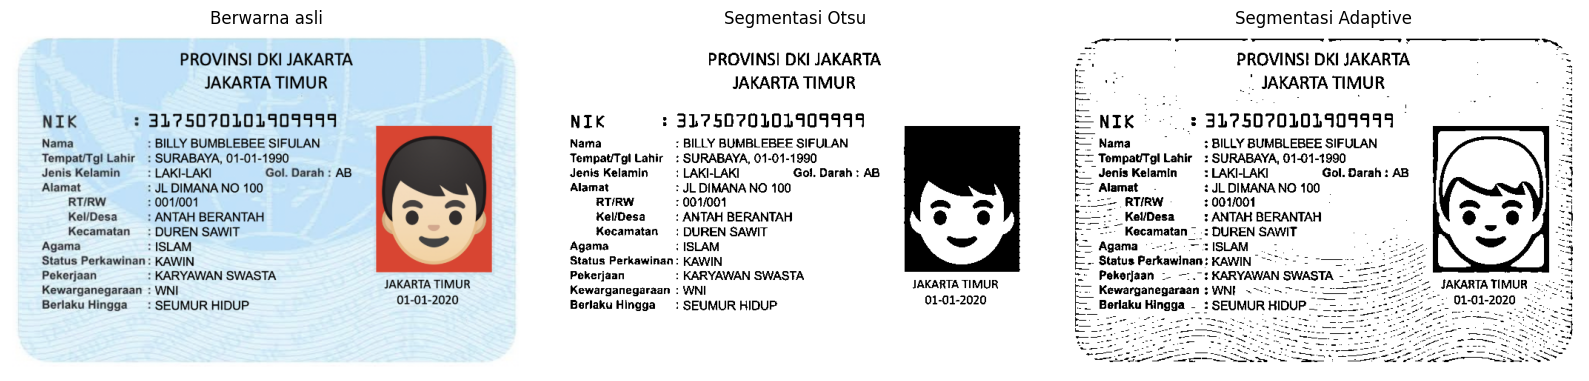

In [18]:
ocr_src = cv2.cvtColor(cv2.imread(resolve_image("ktp_fulan.jpg")), cv2.COLOR_BGR2RGB)
H0, W0 = ocr_src.shape[:2]
gray0 = cv2.cvtColor(ocr_src, cv2.COLOR_RGB2GRAY)

# Otsu
_, otsu_img = cv2.threshold(gray0, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
# Adaptive
adap_img = cv2.adaptiveThreshold(gray0, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                 cv2.THRESH_BINARY, 31, 10)

citra_ocr = {
    "Berwarna asli":     ocr_src,
    "Segmentasi Otsu":   cv2.cvtColor(otsu_img, cv2.COLOR_GRAY2RGB),
    "Segmentasi Adaptive": cv2.cvtColor(adap_img, cv2.COLOR_GRAY2RGB),
}

plt.figure(figsize=(16, 5))
for i, (t, g) in enumerate(citra_ocr.items()):
    plt.subplot(1, 3, i + 1); plt.imshow(g, "gray"); plt.title(t); plt.axis("off")
plt.tight_layout(); plt.show()

### Membaca teks & menandai kotak hasil (confidence > 60)

### Berwarna asli ###
PROVINSI DKI JAKARTA
JAKARTA TIMUR

NIK 1 31?50720101401911
Nama : BILLY BUMBLEBEE SIFULAN
Tempat#Tgl Lahir : SURABAYA, 01-01-1990
Jenis Kelamin: LAKI-LAKI Gol. Darah : AB
Alamat : JL DIMANA NO 100

RTIRW : 001/001

KellDesa — : ANTAH BERANTAH

Kecamatan  : DUREN SAWIT
Agama : ISLAM
Status Perkawinan : KAWIN
Pekerjaan : KARYAWAN SWASTA
Kewarganegaraan : WNI JAKARTA TIMUR,
Berlaku Hingga — : SEUMUR HIDUP 01-01-2020

### Segmentasi Otsu ###
PROVINSI DKI JAKARTA
JAKARTA TIMUR

NIK 1 32?5D?0101401111
Nama : BILLY BUMBLEBEE SIFULAN
Tempat/Tgl Lahir : SURABAYA, 01-01-1990
Jenis Kelamin —: LAKI-LAKI Gol. Darah : AB
Alamat : JL DIMANA NO 100

RTIRW :001/001

KellDesa — : ANTAH BERANTAH

Kecamatan: DUREN SAWIT
Agama : ISLAM
Status Perkawinan: KAWIN
Pekerjaan : KARYAWAN SWASTA
Kewarganegaraan : WNI JAKARTA TIMUR
Berlaku Hingga: SEUMUR HIDUP 01-01-2020

### Segmentasi Adaptive ###
——w——— MU
ah PROVINSI DKI JAKARTA T
Fo . JAKARTA TIMUR £
BE NIK “1.1 32295020101409947 5
FE Nam

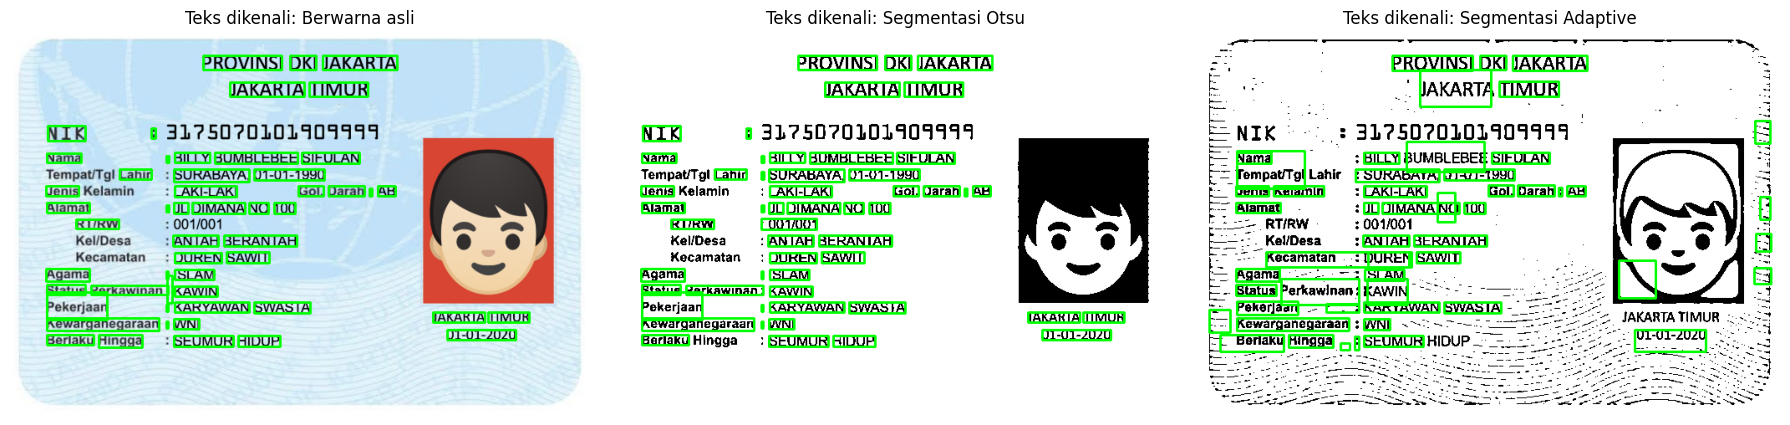

In [19]:
def ocr_baca(rgb_img, psm=6, lang="ind"):
    """Kembalikan (teks penuh, data image_to_data) untuk satu citra."""
    gray = cv2.cvtColor(rgb_img, cv2.COLOR_RGB2GRAY)
    cfg = "--psm {} ".format(psm)
    teks = pytesseract.image_to_string(gray, lang=lang, config=cfg)
    data = pytesseract.image_to_data(gray, lang=lang, config=cfg,
                                     output_type=Output.DICT)
    return teks, data

def gambar_kotak(rgb_img, data, min_conf=60):
    out = rgb_img.copy()
    n = len(data["text"])
    for i in range(n):
        try:
            conf = float(data["conf"][i])
        except Exception:
            conf = -1
        if conf > min_conf and data["text"][i].strip():
            x, y, w, h = (data["left"][i], data["top"][i],
                          data["width"][i], data["height"][i])
            cv2.rectangle(out, (x, y), (x + w, y + h), (0, 255, 0), 2)
    return out

hasil_ocr = {}
if TESS_OK:
    for nama, img in citra_ocr.items():
        teks, data = ocr_baca(img, psm=6, lang="ind")
        hasil_ocr[nama] = {"teks": teks, "data": data}
        print("=" * 70)
        print("###", nama, "###")
        print(teks if teks.strip() else "(tidak ada teks terbaca)")
    plt.figure(figsize=(18, 8))
    for i, (nama, h) in enumerate(hasil_ocr.items()):
        plt.subplot(1, 3, i + 1)
        plt.imshow(gambar_kotak(citra_ocr[nama], h["data"], 60))
        plt.title("Teks dikenali: " + nama); plt.axis("off")
    plt.tight_layout(); plt.show()
else:
    print("Lewati OCR: Tesseract belum terpasang (jalankan di Google Colab).")

### Tabel perbandingan & persentase kecocokan

**Acuan (`TEKS_ACUAN`)** dibentuk otomatis dari **konsensus** token yang muncul pada
setidaknya dua metode dengan confidence tinggi, lalu diambil 10 teratas. Anda dapat
mengedit daftar ini secara manual agar persis sesuai tulisan pada KTP Anda, lalu jalankan ulang sel.

In [20]:
import re

def tokenisasi(data, min_conf=60):
    """Ambil daftar (kata, confidence) dengan confidence > min_conf."""
    toks = []
    for i in range(len(data["text"])):
        t = data["text"][i].strip()
        try:
            c = float(data["conf"][i])
        except Exception:
            c = -1
        if t and c > min_conf:
            toks.append((t, c))
    return toks

def normal(t):
    return re.sub(r"[^a-z0-9]", "", t.lower())

def rata_confidence(data):
    cs = [float(c) for c in data["conf"] if str(c).replace(".", "", 1).lstrip("-").isdigit()
          and float(c) > 0]
    return float(np.mean(cs)) if cs else 0.0

TEKS_ACUAN = []
if TESS_OK and hasil_ocr:
    # --- bentuk acuan konsensus ---
    skor = {}
    for nama, h in hasil_ocr.items():
        for t, c in tokenisasi(h["data"], 60):
            key = normal(t)
            if len(key) >= 3:
                skor.setdefault(key, {"asli": t, "n": 0, "c": 0.0})
                skor[key]["n"] += 1
                skor[key]["c"] += c
    konsensus = [v for v in skor.values() if v["n"] >= 2]
    konsensus.sort(key=lambda v: (v["n"], v["c"]), reverse=True)
    TEKS_ACUAN = [v["asli"] for v in konsensus[:10]]

    # fallback bila konsensus kurang dari 10 -> ambil confidence tertinggi citra berwarna
    if len(TEKS_ACUAN) < 10:
        warna = tokenisasi(hasil_ocr["Berwarna asli"]["data"], 60)
        warna.sort(key=lambda x: x[1], reverse=True)
        for t, _ in warna:
            if normal(t) not in [normal(x) for x in TEKS_ACUAN]:
                TEKS_ACUAN.append(t)
            if len(TEKS_ACUAN) >= 10:
                break

    # ==== EDIT MANUAL (opsional) ====
    # TEKS_ACUAN = ["PROVINSI", "KOTA", "NIK", "NAMA", "FULAN", ...]

    print("Acuan (10 kata/angka):", TEKS_ACUAN)

    ringkasan = {}
    for nama, h in hasil_ocr.items():
        set_tok = {normal(t) for t, _ in tokenisasi(h["data"], 60)}
        cocok = sum(1 for ref in TEKS_ACUAN if normal(ref) in set_tok)
        persen = cocok / max(len(TEKS_ACUAN), 1) * 100
        ringkasan[nama] = {"cocok": cocok, "persen": persen,
                           "conf": rata_confidence(h["data"])}

    print()
    print("{:22s} {:>10s} {:>10s} {:>14s}".format(
        "Citra masukan OCR", "Tepat", "Kecocokan", "Rata2 confidence"))
    print("-" * 60)
    for nama, r in ringkasan.items():
        print("{:22s} {:>10d} {:>9.1f}% {:>14.1f}".format(
            nama, r["cocok"], r["persen"], r["conf"]))

    # tabel detail per kata
    print()
    print("Tabel detail:")
    header = "{:3s} {:>14s} {:>14s} {:>14s} {:>14s}".format(
        "No", "Teks acuan", "Berwarna", "Otsu", "Adaptive")
    print(header); print("-" * len(header))
    for i, ref in enumerate(TEKS_ACUAN, 1):
        baris = ["-"] * 3
        for j, nama in enumerate(["Berwarna asli", "Segmentasi Otsu", "Segmentasi Adaptive"]):
            set_tok = {normal(t) for t, _ in tokenisasi(hasil_ocr[nama]["data"], 60)}
            baris[j] = ref if normal(ref) in set_tok else "-"
        print("{:3d} {:>14s} {:>14s} {:>14s} {:>14s}".format(
            i, ref, baris[0], baris[1], baris[2]))
else:
    print("Lewati tabel OCR: jalankan di Google Colab agar Tesseract tersedia.")

Acuan (10 kata/angka): ['JAKARTA', 'TIMUR', 'DKI', 'SURABAYA,', 'Status', 'KARYAWAN', 'SWASTA', 'Jenis', '100', 'Berlaku']

Citra masukan OCR           Tepat  Kecocokan Rata2 confidence
------------------------------------------------------------
Berwarna asli                  10     100.0%           80.6
Segmentasi Otsu                10     100.0%           81.5
Segmentasi Adaptive            10     100.0%           53.8

Tabel detail:
No      Teks acuan       Berwarna           Otsu       Adaptive
---------------------------------------------------------------
  1        JAKARTA        JAKARTA        JAKARTA        JAKARTA
  2          TIMUR          TIMUR          TIMUR          TIMUR
  3            DKI            DKI            DKI            DKI
  4      SURABAYA,      SURABAYA,      SURABAYA,      SURABAYA,
  5         Status         Status         Status         Status
  6       KARYAWAN       KARYAWAN       KARYAWAN       KARYAWAN
  7         SWASTA         SWASTA         SWAS

### Pertanyaan analisis (Tugas Kelompok)

Isi jawaban berikut berdasarkan keluaran tabel di atas.

1. **Citra masukan mana yang menghasilkan pembacaan paling tepat?**
   Lihat kolom *Kecocokan (%)* — metode dengan persentase tertinggi adalah yang paling tepat,
   umumnya citra **berwarna asli** karena informasi warna membantu segmentasi huruf oleh Tesseract.
2. **Minimal dua kesalahan pembacaan** — misalnya huruf tertukar (O↔0, I↔1, S↔5), kata
   terpotong, atau angka NIK yang tidak terbaca. Bandingkan token OCR dengan `TEKS_ACUAN`.
3. **Apakah segmentasi selalu meningkatkan ketepatan OCR?** Tidak selalu. Segmentasi membantu
   saat latar ramai/banyak noise, tetapi dapat **menghilangkan** detail tipis (garis huruf,
   hologram KTP) sehingga menurunkan akurasi. Lihat apakah Otsu/Adaptive mengungguli citra berwarna.
4. **Pengaruh warna/pola latar** — latar KTP yang berwarna dan berpola (guilloche) menambah
   noise sehingga menyulitkan OCR; latar polos hasil threshold bisa lebih bersih, tetapi bisa
   ikut menghapus teks berwarna kontras rendah.
5. **Apakah confidence tertinggi = kecocokan tertinggi?** Belum tentu. Confidence mengukur
   keyakinan mesin, bukan kebenaran; bandingkan kolom *Rata2 confidence* dengan *Kecocokan (%)*.